### Data preparation for building Mask-RCNN
- step1 : remake boundary thickend mask
- step2 : make



In [1]:
from PIL import Image, ImageFile, ImageOps
from patchify import patchify
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import glob
from tqdm import tqdm
import random




In [2]:

# Predefined size (already resized to 1536x1536)
imx, imy = (1536, 1536)


In [3]:
species_list = ['acapod', 'alllit', 'burspi', 'euclon', 'exostr', 'hakdac']

In [4]:
# dataset内のmskがつく画像すべてについてグレイレベル丸めるようにパスの修正が必要

valid_levels = np.array([0, 64, 128, 192, 255])

for species in species_list:
    base_dir = f'./dataset/{species}/original/mask'
    msk_paths = sorted(glob.glob(os.path.join(base_dir, '**', '*.png'), recursive=True))

    for msk_path in tqdm(msk_paths, desc=f"Processing {species}"):
        img = Image.open(msk_path).convert('L')
        img_arr = np.array(img)
        reshaped = img_arr.reshape(-1, 1)
        distances = np.abs(reshaped - valid_levels)
        closest = valid_levels[np.argmin(distances, axis=1)]
        rounded_img = closest.reshape(img_arr.shape).astype(np.uint8)
        Image.fromarray(rounded_img).save(msk_path)

Processing hakdac: 100%|████████████████████████████████████████████████████| 4/4 [00:00<00:00,  5.09it/s]


Processing: acapod


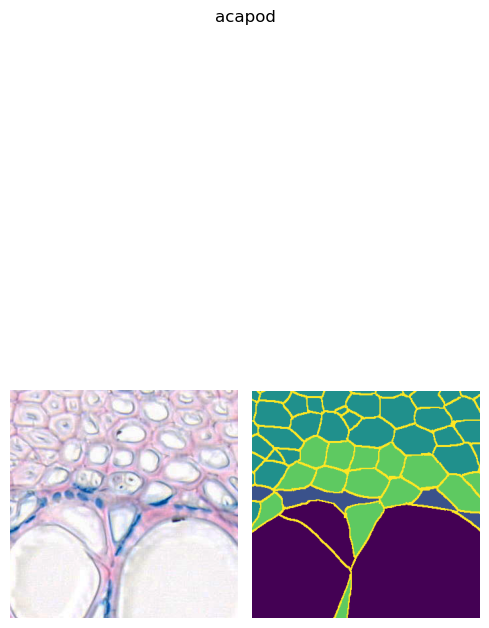

Processing: alllit


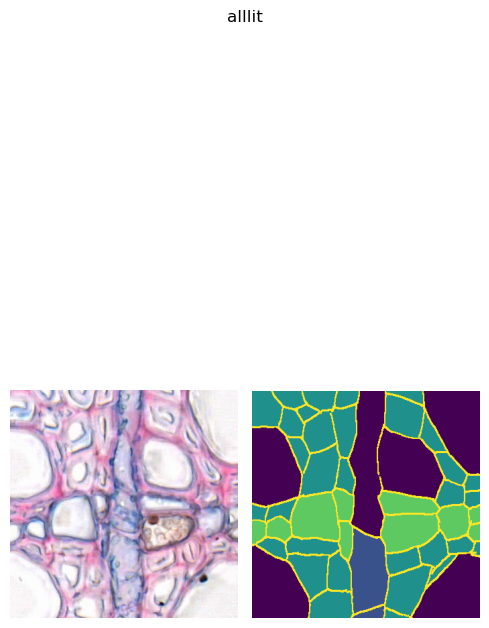

Processing: burspi


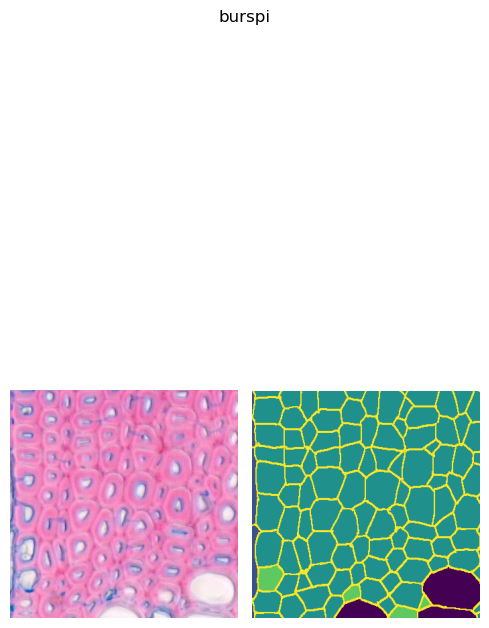

Processing: euclon


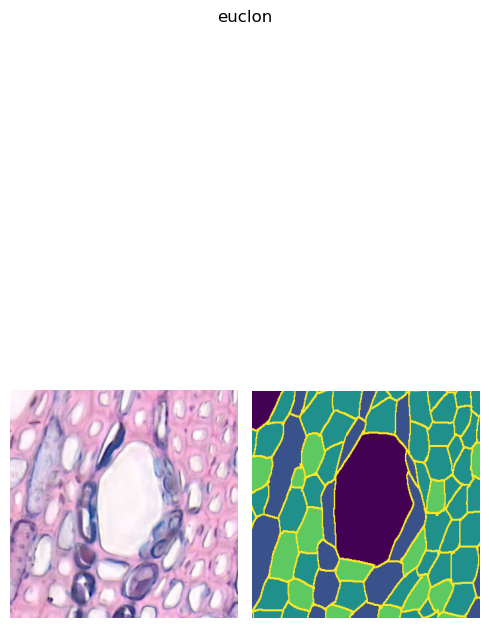

Processing: exostr


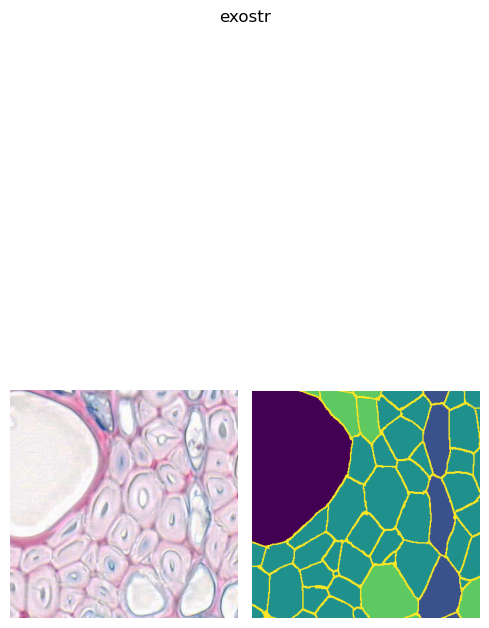

Processing: hakdac


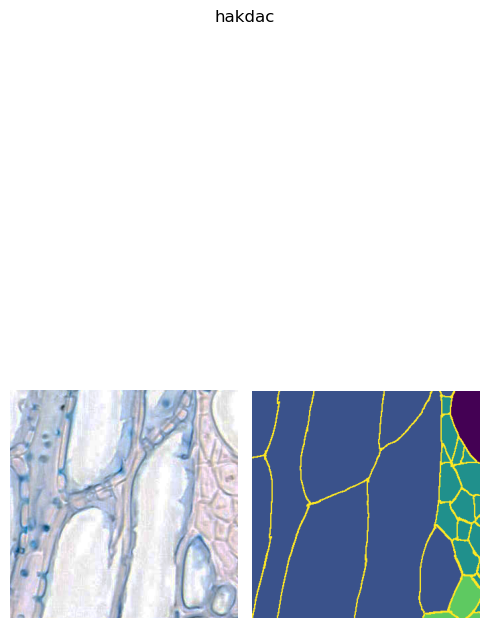

In [5]:

ImageFile.LOAD_TRUNCATED_IMAGES = True

for species in species_list:
    print(f"Processing: {species}")

    msk_paths = sorted(glob.glob(f"dataset/{species}/original/mask/*_msk.png"))
    img_paths = sorted(glob.glob(f"dataset/{species}/original/image/*_img.png"))

    if not msk_paths or not img_paths:
        print("  Skipped (no mask or image found)")
        continue

    imgs = [Image.open(img_paths[0]), Image.open(msk_paths[0])]

    fig, ax = plt.subplots(1, len(imgs), figsize=(5, 10))
    for k, img in enumerate(imgs):
        ax[k].imshow(img.crop((60, 60, 400, 400)))
        ax[k].axis('off')
    plt.suptitle(species)
    plt.tight_layout()
    plt.show()


In [6]:

msk_paths = []
img_paths = []
for species in species_list:
    msk_paths.extend(sorted(glob.glob(f'./dataset/{species}/original/mask/*_msk.png')))
    img_paths.extend(sorted(glob.glob(f'./dataset/{species}/original/image/*_img.png')))


In [7]:

allowed_values = {0, 64, 128, 192, 255}

for path in msk_paths:
    img = Image.open(path).convert("L")
    arr = np.array(img)
    unique_values = set(np.unique(arr))
    if not unique_values.issubset(allowed_values):
        print(f"[WARNING] {path} contains unexpected values: {unique_values - allowed_values}")
    else:
        print(f"[OK] {path} contains only expected values.")

[OK] ./dataset/acapod/original/mask/acapod3_01_msk.png contains only expected values.
[OK] ./dataset/acapod/original/mask/acapod3_02_msk.png contains only expected values.
[OK] ./dataset/acapod/original/mask/acapod4_01_msk.png contains only expected values.
[OK] ./dataset/acapod/original/mask/acapod4_02_msk.png contains only expected values.
[OK] ./dataset/alllit/original/mask/alllit3_01_msk.png contains only expected values.
[OK] ./dataset/alllit/original/mask/alllit3_02_msk.png contains only expected values.
[OK] ./dataset/alllit/original/mask/alllit3_03_msk.png contains only expected values.
[OK] ./dataset/alllit/original/mask/alllit6_01_msk.png contains only expected values.
[OK] ./dataset/burspi/original/mask/burspi2_01_msk.png contains only expected values.
[OK] ./dataset/burspi/original/mask/burspi2_02_msk.png contains only expected values.
[OK] ./dataset/burspi/original/mask/burspi2_03_msk.png contains only expected values.
[OK] ./dataset/burspi/original/mask/burspi4_01_msk.png

In [8]:
# === load the image as a PIL Image object ===
masks_pil = [Image.open(p) for p in msk_paths]
images_pil = [Image.open(p) for p in img_paths]
print("mask files:", len(masks_pil))
print("original files:", len(images_pil))

mask files: 24
original files: 24


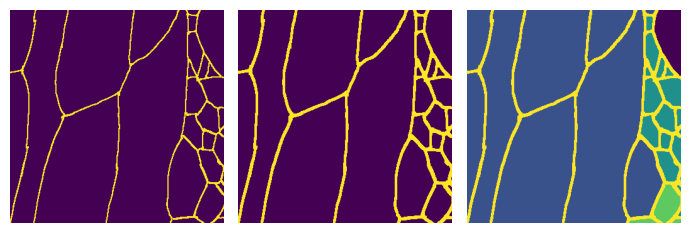

In [9]:
# mask was slightly modified by binary treatement such as dilation and erosion.

# === function definition ===
def binarize_mask(mask):
    return np.where(mask > 230, 255, 0).astype(np.uint8)

def thicken_binary(mask_binary):
    kernel = np.ones((3, 3), np.uint8)
    thick_binary = cv2.dilate(mask_binary, kernel, iterations=2)
    thick_binary = cv2.erode(thick_binary, kernel, iterations=1)
    thick_binary[thick_binary > 0] = 255
    return thick_binary

def overlay_thick_on_mask(original_mask, thick_binary):
    return np.where(thick_binary == 255, 255, original_mask)

bimg = binarize_mask(np.array(imgs[1]))
t_bimg = thicken_binary(bimg)
t_mask = overlay_thick_on_mask(np.array(imgs[1]), t_bimg)

msks = [bimg, t_bimg, t_mask]
fig, ax = plt.subplots(1, len(msks), figsize=(7, 15))
for k, msk in enumerate(msks):
    ax[k].imshow(msk[60:400, 60:400])
    ax[k].axis('off')
plt.tight_layout()
plt.show()


#### Check gray-level
#### 

In [10]:
np.unique(t_bimg)

array([  0, 255], dtype=uint8)

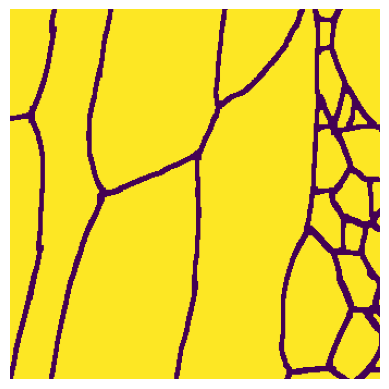

In [11]:

tmp_mask = Image.fromarray(t_bimg)
new_mask = ImageOps.invert(tmp_mask)
plt.imshow(new_mask.crop((60, 60, 400, 400)))
plt.axis('off')
plt.show()


In [12]:
def rand_order(num):
    import random
    r = set(range(num))
    x = set(random.sample(range(0, num), k=int(num * 0.6)))
    y = set(random.sample(list(r - x), k=int((num - len(x)) * 0.6)))
    z = list(r - x - y)
    return [list(x), list(y), z]

###  File allocations

The end of script

In [13]:
for i in range(len(img_paths)):
    # 例: acapod5_01_img.png → save_index = "_acapod5_01"
    save_index = "_" + os.path.splitext(os.path.basename(img_paths[i]))[0].replace('_img', '')
    species_name = os.path.basename(img_paths[i])[:6]

    img = Image.open(img_paths[i]).resize((imy, imx))
    msk = Image.open(msk_paths[i]).resize((imy, imx))
    imgs = [img, msk]

    bimg = binarize_mask(np.array(imgs[1]))
    t_bimg = thicken_binary(bimg)
    t_mask = overlay_thick_on_mask(np.array(imgs[1]), t_bimg)
    tmp_mask = Image.fromarray(t_mask).convert("L")
    new_mask = ImageOps.invert(tmp_mask)

    for key_1 in [256, 512]:
        patches_1 = patchify(np.array(imgs[0])[:, :, :3], (key_1, key_1, 3), step=key_1)
        patches_go_1 = patches_1.reshape((-1, key_1, key_1, 3))

        patches_2 = patchify(np.array(new_mask), (key_1, key_1), step=key_1)
        patches_go_2 = patches_2.reshape((-1, key_1, key_1))

        imgs_num = int(imx / key_1) * int(imy / key_1)
        flist = rand_order(imgs_num)

        for k, key_2 in enumerate(['train', 'valid', 'test']):
            img_dir = f"dataset/{species_name}/png_{key_1}/image/{key_2}/"
            msk_dir = f"dataset/{species_name}/png_{key_1}/mask/{key_2}/"
            os.makedirs(img_dir, exist_ok=True)
            os.makedirs(msk_dir, exist_ok=True)

            for j in flist[k]:
                img_f_1 = Image.fromarray(patches_go_1[j]).convert('RGB')
                img_f_1.save(os.path.join(img_dir, f'{j:04}{save_index}.png'))

                img_f_2 = Image.fromarray(patches_go_2[j]).convert('L')
                img_f_2.save(os.path.join(msk_dir, f'{j:04}{save_index}.png'))

